1. 데이터를 수집하고, 분석하는 과정의 프로세스 = 플로우(흐름) 늘 항상 동일한 패턴이 존재 x
2. Data Engineer
- Data Provider(데이터분석을 할 수 있도록 데이터 공급 파이프라인 기획.개발.제작)
- Data Analytics(공급된 데이터의 중요도에 따라서 사용여부 판단, 해당 데이터 패턴,인사이트,도출)
- Data Consumer(데이터공급 & 분석 -> 비즈니스 의사결정 및 마케팅 전략수립 등 지원하기 위한 역할 // BI)
3. 데이터를 취급하는 가장 일반적 & 보편적인 방법
- EDA -> NLP -> LDA -> DataLab
- EDA : Exploratory Data Analysis = 탐색적 데이터 분석 과정
- crawling > 1000개의 데이터 수집 > 해당 데이터가 의미하는 것이 무엇인지 파악 (데이터의 형태, 유형, 크기, 최소, 최대, 평균, 이상치, 사분위 등)
- NLP : Natural Language Processing = 자연어 처리 = 형태소 분석
- 텍스트 기반의 데이터를 주로 명사 중심으로 전처리 (정제 등)
- 특정 키워드의 언급 // 사용량 높음 / 낮음 (긍.부정)
- 긍정 (A / B / C)
- LDA : Latent Dirichlet Allocation = 잠재 디리클레 할당
- NLP 과정을 통해서 도출된 텍스트들의 연관성 및 공통분모에 따라서 키워드를 분류 => 몇 가지의 Topic
- 진짜 고객들의 숨겨진 = 잠재되어있는 의도가 도출
- DataLab = EDA -> NLP -> LDA -> 고객들의 관심도 변화 추이 등을 시각화 / 전략수립을 위한 데이터구축

In [ ]:
# 우리가 신규 북 플랫폼을 구축 & 마케팅 주제
# 수강생분들과 경쟁사 yes24 사이트 데이터 크롤링
# 수요분석 "네이버 광고센터" 특정 책과 관련 키워드 중심 연관키워드 다운로드
# 해당 키워드를 활용, 최근 사용자들은 책과 관련 어떤 관심 EDA, NLP, LDA 기법 찾아내자
# 경쟁사 과연 수요에 맞는 전략 확인, 마케팅 전략

In [5]:
import pandas as pd

FILE_PATH = "연관키워드 20260920 1631.xlsx"

df = pd.read_excel(FILE_PATH, header=1)

df.head()

,연관키워드,월간검색수(PC),월간검색수(모바일),월평균클릭수(PC),월평균클릭수(모바일),월평균클릭률(PC),월평균클릭률(모바일),경쟁정도,월평균노출 광고수
0,도서,"8,000","13,600",84.0,239.2,1.11%,1.88%,높음,10
1,독서,"1,110","3,850",0.5,10.4,0.05%,0.29%,높음,10
2,책,"6,860","22,600",44.1,192,0.68%,0.91%,높음,10
3,베스트셀러,"13,400","36,400",118.6,"1,031.9",0.93%,3.02%,높음,10
4,인터넷서점,"1,650","3,040",78.3,218.8,4.99%,7.67%,높음,10


In [7]:
df.columns = [
    "keyword",
    "search_pc",
    "search_mobile",
    "click_pc",
    "click_mobile",
    "ctr_pc",
    "ctr_mobile",
    "competition",
    "ad_count",
]

df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count
0,도서,"8,000","13,600",84.0,239.2,1.11%,1.88%,높음,10
1,독서,"1,110","3,850",0.5,10.4,0.05%,0.29%,높음,10
2,책,"6,860","22,600",44.1,192,0.68%,0.91%,높음,10
3,베스트셀러,"13,400","36,400",118.6,"1,031.9",0.93%,3.02%,높음,10
4,인터넷서점,"1,650","3,040",78.3,218.8,4.99%,7.67%,높음,10


In [8]:
# EDA

df.shape

(1000, 9)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   keyword        1000 non-null   object 
 1   search_pc      1000 non-null   object 
 2   search_mobile  1000 non-null   object 
 3   click_pc       1000 non-null   float64
 4   click_mobile   1000 non-null   object 
 5   ctr_pc         1000 non-null   object 
 6   ctr_mobile     1000 non-null   object 
 7   competition    1000 non-null   object 
 8   ad_count       1000 non-null   int64  
dtypes: float64(1), int64(1), object(7)
memory usage: 70.4+ KB


In [10]:
df.tail()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count
995,읽으면서바로써먹는,240,"2,120",1.6,37.8,0.73%,1.92%,높음,10
996,디즈니골든명작,70,630,0.6,21,0.9%,3.54%,중간,8
997,독서클럽,80,260,0.5,1.5,0.64%,0.58%,높음,10
998,책놀이,150,200,0.5,0.8,0.34%,0.39%,높음,10
999,미술수업,100,230,0.3,1,0.33%,0.48%,높음,10


In [13]:
df[df["keyword"].isna()]

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count


In [12]:
df["keyword"].duplicated().sum()

np.int64(0)

In [27]:
number_cols = [
    "search_pc",
    "search_mobile",
    "click_pc",
    "click_mobile",
    "ad_count"
]

for col in number_cols :
    df[col] = df[col].astype(str).str.replace(",", "", regex=False) # 이스케이프 시퀀스 = 특수문자열 \ . \n
    df[col] = pd.to_numeric(df[col], errors="coerce") # "1000" => 1000 // "개똥이" => NA 10 >=

# for col in number_cols :
#     df[col] = pd.to_numeric(
#         df[col].astype(str).str.replace(",", ""),
#         errors="coerce"
#     ).astype("Int64")

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   keyword        1000 non-null   object 
 1   search_pc      732 non-null    float64
 2   search_mobile  885 non-null    float64
 3   click_pc       1000 non-null   float64
 4   click_mobile   1000 non-null   float64
 5   ctr_pc         1000 non-null   object 
 6   ctr_mobile     1000 non-null   object 
 7   competition    1000 non-null   object 
 8   ad_count       1000 non-null   int64  
dtypes: float64(4), int64(1), object(4)
memory usage: 70.4+ KB


In [20]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count
0,도서,8000.0,13600.0,84.0,239.2,1.11%,1.88%,높음,10
1,독서,1110.0,3850.0,0.5,10.4,0.05%,0.29%,높음,10
2,책,6860.0,22600.0,44.1,192.0,0.68%,0.91%,높음,10
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93%,3.02%,높음,10
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99%,7.67%,높음,10


In [29]:
ctr_cols = [
    "ctr_pc",
    "ctr_mobile"
]

for col in ctr_cols :
    df[col] = df[col].astype(str).str.replace("%", "", regex=False) # 이스케이프 시퀀스 = 특수문자열 \ . \n
    df[col] = pd.to_numeric(df[col], errors="coerce") # "1000" => 1000 // "개똥이" =>

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   keyword        1000 non-null   object 
 1   search_pc      732 non-null    float64
 2   search_mobile  885 non-null    float64
 3   click_pc       1000 non-null   float64
 4   click_mobile   1000 non-null   float64
 5   ctr_pc         577 non-null    float64
 6   ctr_mobile     713 non-null    float64
 7   competition    1000 non-null   object 
 8   ad_count       1000 non-null   int64  
dtypes: float64(6), int64(1), object(2)
memory usage: 70.4+ KB


In [30]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count
0,도서,8000.0,13600.0,84.0,239.2,1.11,1.88,높음,10
1,독서,1110.0,3850.0,0.5,10.4,0.05,0.29,높음,10
2,책,6860.0,22600.0,44.1,192.0,0.68,0.91,높음,10
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10


In [33]:
df["search_total"] = df["search_pc"] + df["search_mobile"]
df["click_total"] = df["click_pc"] + df["click_mobile"]
df["pc_ratio"] = df["search_pc"] / df["search_total"] * 100
df["mobile_ratio"] = df["search_mobile"] / df["search_total"] * 100

In [34]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio
0,도서,8000.0,13600.0,84.0,239.2,1.11,1.88,높음,10,21600.0,323.2,37.037037,62.962963
1,독서,1110.0,3850.0,0.5,10.4,0.05,0.29,높음,10,4960.0,10.9,22.379032,77.620968
2,책,6860.0,22600.0,44.1,192.0,0.68,0.91,높음,10,29460.0,236.1,23.285811,76.714189
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763


In [35]:
df.describe()

,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,ad_count,search_total,click_total,pc_ratio,mobile_ratio
count,732.000000,885.000000,1000.00000,1000.000000,577.000000,713.000000,1000.000000,723.000000,1000.000000,723.000000,723.000000
mean,399.699454,879.254237,2.14070,11.852000,2.525234,2.761711,6.659000,1475.919779,13.992700,25.606997,74.393003
std,2286.124545,3787.780590,11.67392,67.833079,4.370142,3.090283,3.196707,5746.664269,77.396964,12.967154,12.967154
min,10.000000,10.000000,0.00000,0.000000,0.030000,0.040000,0.000000,20.000000,0.000000,2.500000,10.000000
25%,20.000000,30.000000,0.00000,0.000000,0.410000,0.580000,3.000000,90.000000,0.300000,16.507694,66.666667
50%,50.000000,120.000000,0.20000,0.900000,1.240000,1.670000,7.000000,260.000000,1.000000,23.076923,76.923077
75%,180.000000,460.000000,0.70000,3.800000,2.950000,3.760000,10.000000,825.000000,4.600000,33.333333,83.492306
max,47600.000000,79300.000000,183.80000,1462.400000,50.000000,25.000000,10.000000,88670.000000,1641.400000,90.000000,97.500000


In [37]:
df[
    [
        "search_pc",
        "search_mobile",
        "click_pc",
        "click_mobile",
        "ctr_pc",
        "ctr_mobile",
        "ad_count",
        "search_total",
        "click_total",
        "pc_ratio",
        "mobile_ratio"
    ]
].describe().round(2)

,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,ad_count,search_total,click_total,pc_ratio,mobile_ratio
count,732.00,885.00,1000.00,1000.00,577.00,713.00,1000.00,723.00,1000.00,723.00,723.00
mean,399.70,879.25,2.14,11.85,2.53,2.76,6.66,1475.92,13.99,25.61,74.39
std,2286.12,3787.78,11.67,67.83,4.37,3.09,3.20,5746.66,77.40,12.97,12.97
min,10.00,10.00,0.00,0.00,0.03,0.04,0.00,20.00,0.00,2.50,10.00
25%,20.00,30.00,0.00,0.00,0.41,0.58,3.00,90.00,0.30,16.51,66.67
50%,50.00,120.00,0.20,0.90,1.24,1.67,7.00,260.00,1.00,23.08,76.92
75%,180.00,460.00,0.70,3.80,2.95,3.76,10.00,825.00,4.60,33.33,83.49
max,47600.00,79300.00,183.80,1462.40,50.00,25.00,10.00,88670.00,1641.40,90.00,97.50


In [39]:
top_search = df.sort_values("search_total", ascending=False).head(20)

top_search[["keyword", "search_pc", "search_mobile", "search_total"]]

,keyword,search_pc,search_mobile,search_total
23,도서관,9370.0,79300.0,88670.0
279,일일수학,47600.0,16300.0,63900.0
3,베스트셀러,13400.0,36400.0,49800.0
242,시나공,29200.0,19300.0,48500.0
383,제본,10000.0,34600.0,44600.0
273,문화누리카드사용처,4540.0,25100.0,29640.0
2,책,6860.0,22600.0,29460.0
40,베스트셀러순위,3870.0,19500.0,23370.0
0,도서,8000.0,13600.0,21600.0
275,공모전,9700.0,11300.0,21000.0


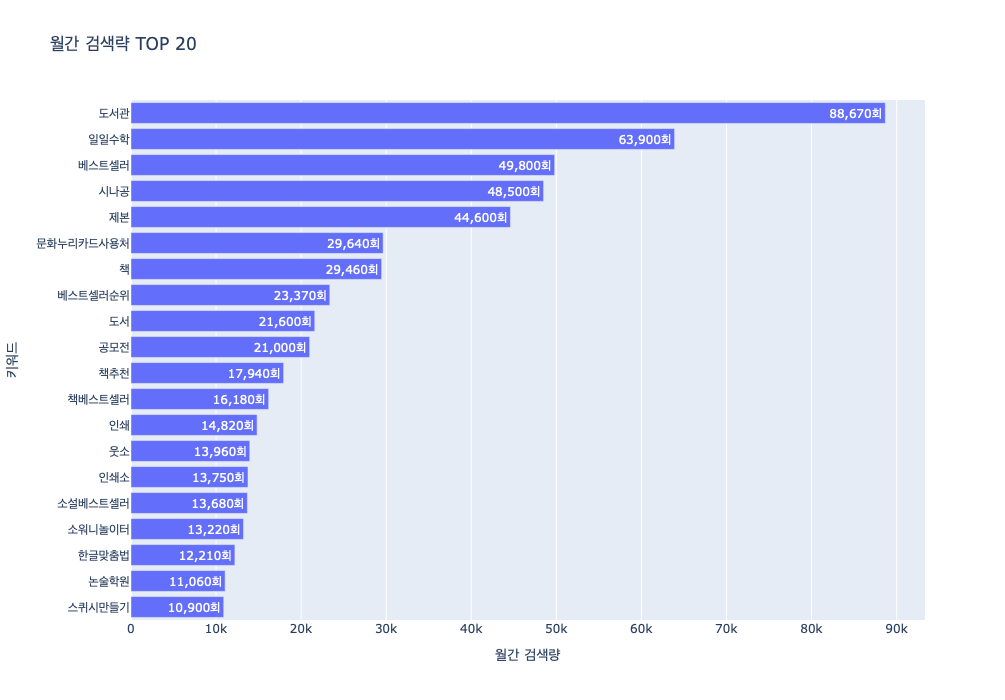

In [47]:
import plotly.express as px

fig = px.bar(
    top_search,
    x="search_total",
    y="keyword",
    title="월간 검색략 TOP 20",
    labels={
        "search_total": "월간 검색량",
        "keyword": "키워드"
    },
    text="search_total"
)

fig.update_layout(
    yaxis={
        "categoryorder": "total ascending"
    },
    height=700
)

fig.update_traces(
    texttemplate="%{text:,.0f}회"
)

fig.show()

In [48]:
top_search.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio
23,도서관,9370.0,79300.0,7.3,40.9,0.09,0.06,높음,3,88670.0,48.2,10.567272,89.432728
279,일일수학,47600.0,16300.0,43.0,17.0,0.14,0.30,낮음,1,63900.0,60.0,74.491393,25.508607
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369
242,시나공,29200.0,19300.0,29.0,117.8,0.11,0.66,중간,3,48500.0,146.8,60.206186,39.793814
383,제본,10000.0,34600.0,183.8,438.9,1.93,1.33,중간,8,44600.0,622.7,22.421525,77.578475


In [53]:
top20_device = top_search.melt(
    id_vars = "keyword",
    value_vars=[
        "search_pc",
        "search_mobile"
    ],
    var_name="device",
    value_name="search_volume"
)

top20_device

# 전체 데이터의 탐색적 데이터 분석과정 (정제)
# 주요 인기 키워드 20위 선별
# 인기 키워드의 pc, mobile의 인기 정도 확인

,keyword,device,search_volume
0,도서관,search_pc,9370.0
1,일일수학,search_pc,47600.0
2,베스트셀러,search_pc,13400.0
3,시나공,search_pc,29200.0
4,제본,search_pc,10000.0
5,문화누리카드사용처,search_pc,4540.0
6,책,search_pc,6860.0
7,베스트셀러순위,search_pc,3870.0
8,도서,search_pc,8000.0
9,공모전,search_pc,9700.0


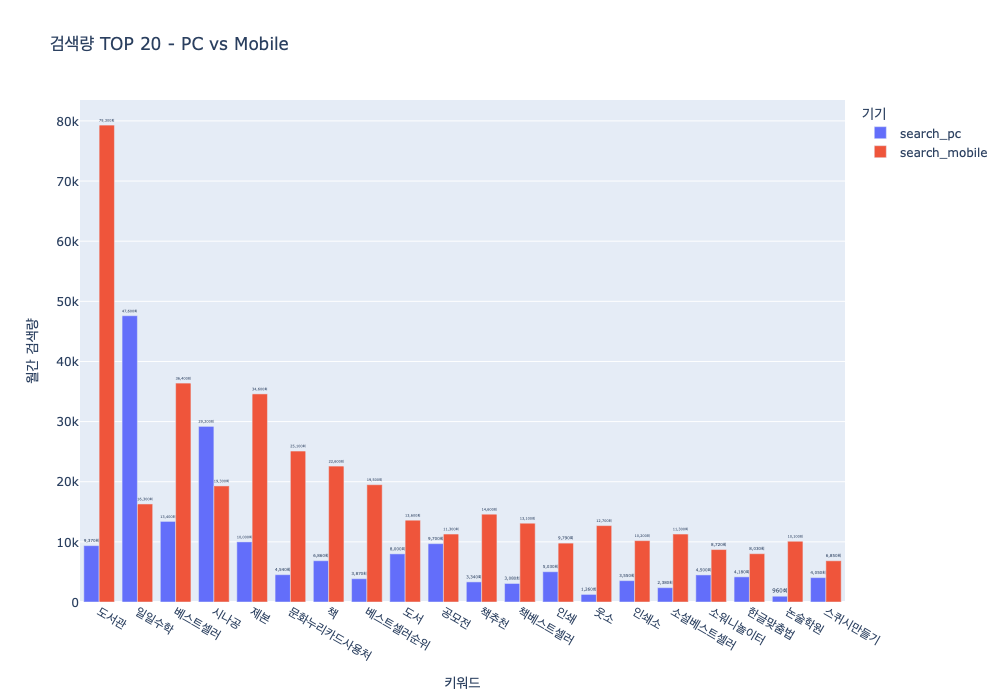

In [65]:
import plotly.express as px

fig = px.bar(
    top20_device,
    x="keyword",
    y="search_volume",
    title="검색량 TOP 20 - PC vs Mobile",
    color="device",
    barmode="group",
    labels={
        "search_volume": "월간 검색량",
        "keyword": "키워드",
        "device": "기기"
    },
    text_auto=True
    # text="search_volume"
)

fig.update_layout(
    width=1200,
    height=700
)

fig.update_traces(
    texttemplate="%{y:,.0f}회",
    textposition="outside",
    cliponaxis=False
)

fig.show()

In [ ]:
# 그로스 마케터
# 1) 네이버 연관키워드 EDA
# 2) 네이버 연관키워드 주요 키워드 20개 추출
# 3) 20개 키워드 PC, Mobile 편향 조사 : Mobile // PC : 수험생, 시험공부 관련 책
# 4) Mobile 중심으로 키워드 재분석

In [66]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio
0,도서,8000.0,13600.0,84.0,239.2,1.11,1.88,높음,10,21600.0,323.2,37.037037,62.962963
1,독서,1110.0,3850.0,0.5,10.4,0.05,0.29,높음,10,4960.0,10.9,22.379032,77.620968
2,책,6860.0,22600.0,44.1,192.0,0.68,0.91,높음,10,29460.0,236.1,23.285811,76.714189
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763


In [69]:
mobile_keyword = df[df["search_total"] >= 1000].sort_values("mobile_ratio", ascending=False).head(20).copy()

In [71]:
mobile_keyword[
    ["keyword", "search_pc", "search_mobile", "mobile_ratio"]
].round(2)

,keyword,search_pc,search_mobile,mobile_ratio
423,말이야와친구들,150.0,3390.0,95.76
965,국어문제집,160.0,1750.0,91.62
360,논술학원,960.0,10100.0,91.32
633,독서학원,110.0,1110.0,90.98
495,웃소,1260.0,12700.0,90.97
325,문화누리사용처,330.0,3240.0,90.76
742,논술준비,130.0,1190.0,90.15
508,코믹스,250.0,2210.0,89.84
995,읽으면서바로써먹는,240.0,2120.0,89.83
23,도서관,9370.0,79300.0,89.43


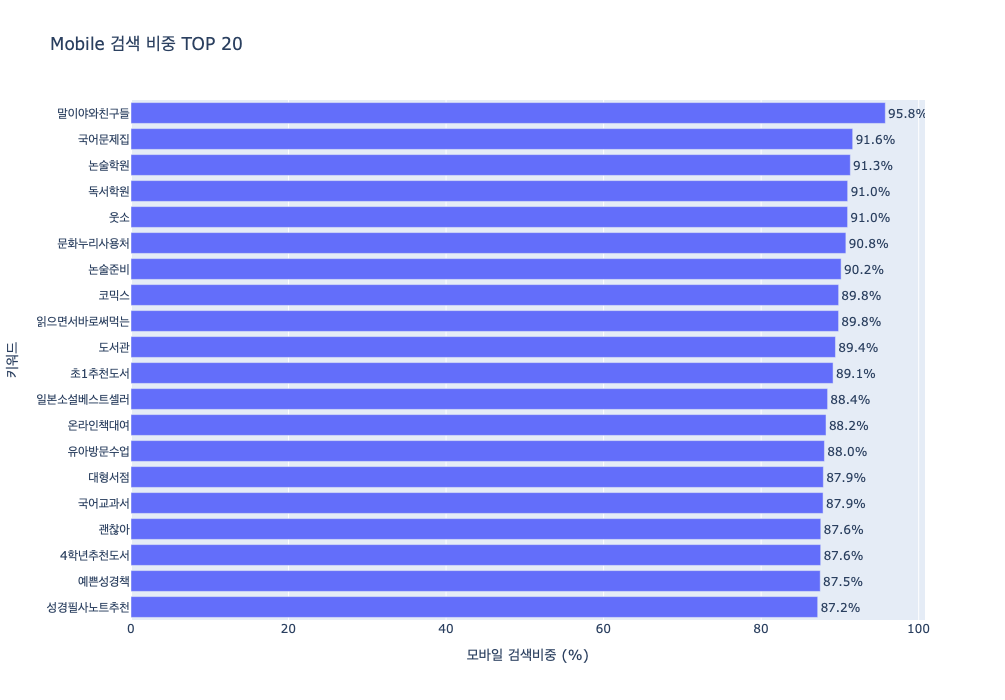

In [74]:
import plotly.express as px

fig = px.bar(
    mobile_keyword,
    x="mobile_ratio",
    y="keyword",
    title="Mobile 검색 비중 TOP 20",
    labels={
        "mobile_ratio": "모바일 검색비중 (%)",
        "keyword": "키워드"
    },
    hover_data=[
        "search_total",
        "search_mobile"
    ],
    # text_auto=True
    text="mobile_ratio"
)

fig.update_layout(
    yaxis={
        "categoryorder": "total ascending"
    },
    height=700
)

fig.update_traces(
    texttemplate="%{text:,.1f}%",
    textposition="outside"
)

fig.show()

In [ ]:
# 그로스 마케터
# 1) 네이버 연관키워드 EDA
# 2) 네이버 연관키워드 주요 키워드 20개 추출
# 3) 20개 키워드 PC, Mobile 편향 조사 : Mobile // PC : 수험생, 시험공부 관련 책
# 4) Mobile 중심으로 키워드 재분석 - 1 : 전체 검색량 1000건 이상 + 모바일 클릭률 내림차순 : 웃소, 국어, 논술, 독서, 일본베스트셀러, 온라인책대여
# 5) Mobile 중심으로 키워드 재분석 - 2 : 모바일 검색 500건 이상 + 모바일 클릭률 내림차순 :

In [75]:
df.describe()

,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,ad_count,search_total,click_total,pc_ratio,mobile_ratio
count,732.000000,885.000000,1000.00000,1000.000000,577.000000,713.000000,1000.000000,723.000000,1000.000000,723.000000,723.000000
mean,399.699454,879.254237,2.14070,11.852000,2.525234,2.761711,6.659000,1475.919779,13.992700,25.606997,74.393003
std,2286.124545,3787.780590,11.67392,67.833079,4.370142,3.090283,3.196707,5746.664269,77.396964,12.967154,12.967154
min,10.000000,10.000000,0.00000,0.000000,0.030000,0.040000,0.000000,20.000000,0.000000,2.500000,10.000000
25%,20.000000,30.000000,0.00000,0.000000,0.410000,0.580000,3.000000,90.000000,0.300000,16.507694,66.666667
50%,50.000000,120.000000,0.20000,0.900000,1.240000,1.670000,7.000000,260.000000,1.000000,23.076923,76.923077
75%,180.000000,460.000000,0.70000,3.800000,2.950000,3.760000,10.000000,825.000000,4.600000,33.333333,83.492306
max,47600.000000,79300.000000,183.80000,1462.400000,50.000000,25.000000,10.000000,88670.000000,1641.400000,90.000000,97.500000


In [76]:
top_ctr_mobile = df[df["search_mobile"] >= 500].sort_values("ctr_mobile", ascending=False).head(20).copy()

In [77]:
top_ctr_mobile

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio
573,무협소설,1010.0,5170.0,49.7,623.4,5.25,12.97,높음,10,6180.0,673.1,16.343042,83.656958
508,코믹스,250.0,2210.0,6.3,238.4,2.73,11.69,중간,6,2460.0,244.7,10.162602,89.837398
293,문화누리카드온라인사용처,560.0,2420.0,33.4,244.4,6.25,10.57,높음,10,2980.0,277.8,18.791946,81.208054
973,온라인책대여,180.0,1350.0,7.7,127.7,4.54,10.15,중간,8,1530.0,135.4,11.764706,88.235294
51,책구매사이트,260.0,910.0,14.9,81.0,6.06,9.58,높음,10,1170.0,95.9,22.222222,77.777778
98,서점당일배송,50.0,680.0,2.3,58.9,4.43,9.18,높음,9,730.0,61.2,6.849315,93.150685
42,책구매,320.0,800.0,16.7,63.4,5.50,8.39,높음,10,1120.0,80.1,28.571429,71.428571
220,성경책구입,90.0,540.0,4.7,41.8,5.42,8.00,높음,7,630.0,46.5,14.285714,85.714286
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763
307,문화누리카드가맹점,690.0,3000.0,20.1,204.0,3.06,7.34,높음,10,3690.0,224.1,18.699187,81.300813


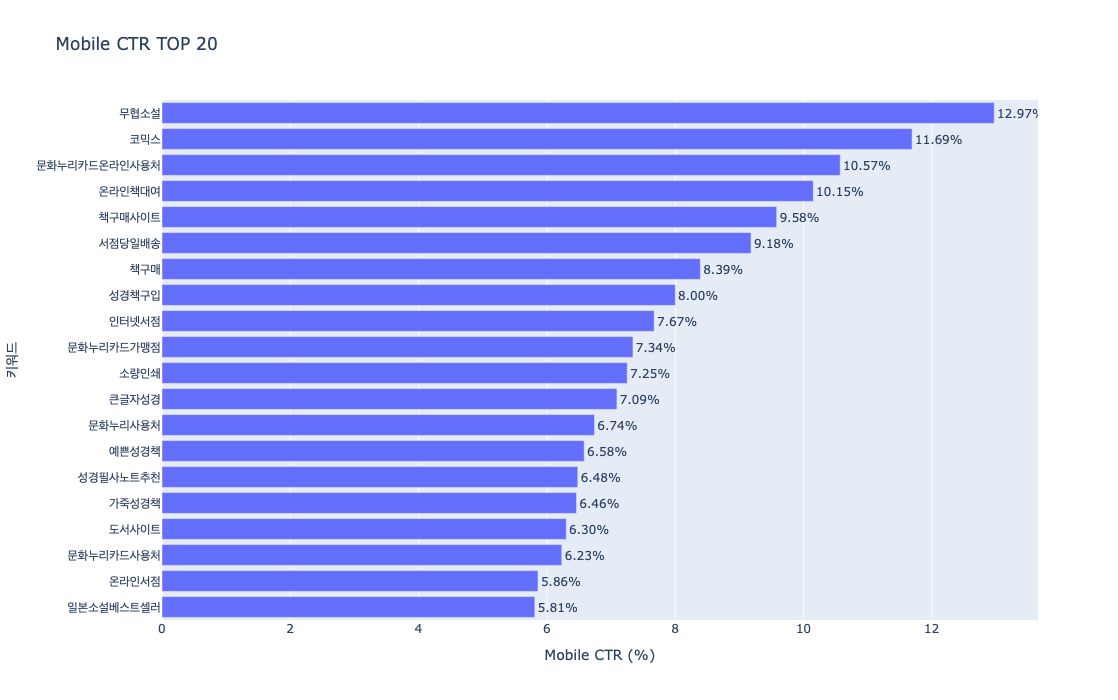

In [78]:
import plotly.express as px

fig = px.bar(
    top_ctr_mobile,
    x="ctr_mobile",
    y="keyword",
    title="Mobile CTR TOP 20",
    labels={
        "ctr_mobile": "Mobile CTR (%)",
        "keyword": "키워드"
    },
    hover_data=[
        "click_mobile",
        "search_mobile",
        "competition"
    ],
    # text_auto=True
    text="ctr_mobile"
)

fig.update_layout(
    yaxis={
        "categoryorder": "total ascending"
    },
    height=700
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.show()

In [ ]:
# 그로스 마케터
# 1) 네이버 연관키워드 EDA
# 2) 네이버 연관키워드 주요 키워드 20개 추출
# 3) 20개 키워드 PC, Mobile 편향 조사 : Mobile // PC : 수험생, 시험공부 관련 책
# 4) Mobile 중심으로 키워드 재분석 - 1 : 전체 검색량 1000건 이상 + 모바일 클릭률 내림차순 : 웃소, 국어, 논술, 독서, 일본베스트셀러, 온라인책대여
# 5) Mobile 중심으로 키워드 재분석 - 2 : 모바일 검색 500건 이상 + 모바일 클릭률 내림차순 : 일본베스트셀러, 온라인책대여, 성경 등 종교관련, 소량인쇄
# 6) PC 중심으로 키워드 분석 : PC 검색 500건 이상 + PC 클릭률 내림차순 : 소량인쇄, 도서순위, 도서검색 등 키워드 (모바일과는 살짝 다른 느낌)

In [79]:
top_ctr_pc = df[df["search_pc"] >= 500].sort_values("ctr_pc", ascending=False).head(20).copy()

In [80]:
top_ctr_pc

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio
375,소량인쇄,1260.0,1010.0,75.8,68.6,6.33,7.25,높음,10,2270.0,144.4,55.506608,44.493392
293,문화누리카드온라인사용처,560.0,2420.0,33.4,244.4,6.25,10.57,높음,10,2980.0,277.8,18.791946,81.208054
573,무협소설,1010.0,5170.0,49.7,623.4,5.25,12.97,높음,10,6180.0,673.1,16.343042,83.656958
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763
393,인쇄업체,760.0,460.0,30.7,25.8,4.22,5.87,높음,10,1220.0,56.5,62.295082,37.704918
6,온라인서점,680.0,1490.0,26.7,83.4,4.19,5.86,높음,10,2170.0,110.1,31.336406,68.663594
273,문화누리카드사용처,4540.0,25100.0,179.0,1462.4,4.17,6.23,높음,10,29640.0,1641.4,15.317139,84.682861
373,포스터제작,2820.0,3280.0,84.7,116.2,3.15,3.76,높음,7,6100.0,200.9,46.229508,53.770492
307,문화누리카드가맹점,690.0,3000.0,20.1,204.0,3.06,7.34,높음,10,3690.0,224.1,18.699187,81.300813
159,교보문고베스트셀러순위,560.0,1830.0,14.2,92.9,2.67,5.44,중간,3,2390.0,107.1,23.430962,76.569038


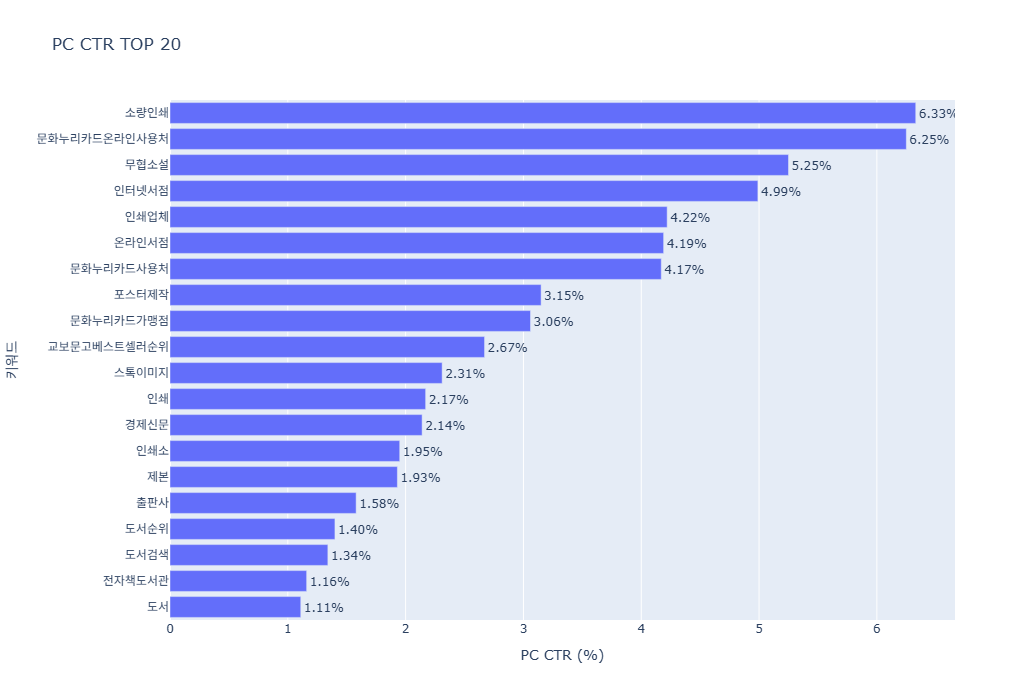

In [81]:
import plotly.express as px

fig = px.bar(
    top_ctr_pc,
    x="ctr_pc",
    y="keyword",
    title="PC CTR TOP 20",
    labels={
        "ctr_pc": "PC CTR (%)",
        "keyword": "키워드"
    },
    # text_auto=True
    text="ctr_pc"
)

fig.update_layout(
    yaxis={
        "categoryorder": "total ascending"
    },
    height=700
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.show()

In [ ]:
# 그로스 마케터
# 1) 네이버 연관키워드 EDA
# 2) 네이버 연관키워드 주요 키워드 20개 추출
# 3) 20개 키워드 PC, Mobile 편향 조사 : Mobile // PC : 수험생, 시험공부 관련 책
# 4) Mobile 중심으로 키워드 재분석 - 1 : 전체 검색량 1000건 이상 + 모바일 클릭률 내림차순 : 웃소, 국어, 논술, 독서, 일본베스트셀러, 온라인책대여
# 5) Mobile 중심으로 키워드 재분석 - 2 : 모바일 검색 500건 이상 + 모바일 클릭률 내림차순 : 일본베스트셀러, 온라인책대여, 성경 등 종교관련, 소량인쇄
# 6) PC 중심으로 키워드 분석 : PC 검색 500건 이상 + PC 클릭률 내림차순 : 소량인쇄, 도서순위, 도서검색 등 키워드 (모바일과는 살짝 다른 느낌)
# 7) 세부 데이터 상관관계 :
# - 검색량 & Mobile CTR : 검색량이 높은 키워드를 기반 컨텐츠 마케팅